# To convert the temperature into Celsius °C to Fahrenheit °F based on the user inputs

In [41]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated, List
import operator

In [42]:
# function to convert Celsius to Fahrenheit

def celsius_to_fahrenheit(state: TempState) -> TempState:

    celsius = state['value']
    state['result']= (celsius * 9 /5) +32

    return state


In [43]:
# function to convert fahrenheit to celsius

def fahrenheit_to_celsius(sate: TempState) -> TempState:

    fahrenheit = state['value']
    state['result'] =  (fahrenheit - 32) * 5 /9 
    return StateGraph


In [44]:
# router when on the condition

def route_temperature(state: TempState) -> TempState:

    unit = state['unit']

    if unit == 'celsius':
        return 'CF'
    
    elif unit == 'fahrenheit':
        return 'FC'
    
    else:
        raise ValueError('Unit must be  in celsius or fahrenheit')


In [52]:
def value(state: TempState) -> TempState:

    value = state['value']
    return state

In [45]:
# state
class TempState(TypedDict):

    value: float
    unit: str   # 'C' or 'F'
    result: float | None  

In [57]:
# build the graph

graph = StateGraph(TempState)

graph.add_node('value', value)
graph.add_node('celsius', celsius_to_fahrenheit)
graph.add_node('fahrenheit', fahrenheit_to_celsius)

# add the edge
graph.add_edge(START, 'value')

# condition edges
graph.add_conditional_edges('value', route_temperature,
                            {'CF': 'celsius',
                             'FC': 'fahrenheit'
                            }
                           )



# End after conversion
graph.add_edge('celsius', END)
graph.add_edge('fahrenheit', END)

In [58]:
workflow = graph.compile()

In [59]:
workflow.invoke({
 'value': 25.5,
 'unit': 'celsius',
 'result': None
})

{'value': 25.5, 'unit': 'celsius', 'result': 77.9}

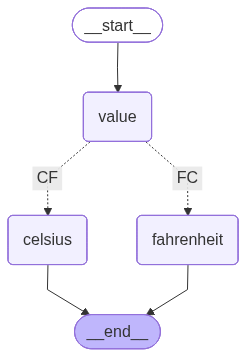

In [60]:
workflow